In [9]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
%matplotlib inline

In [10]:
df = pd.read_csv("../data/simpson_paradox.csv")
print(f"Всего пользователей: {len(df):,}")

# Конверсия в целом
control = df[df["group"] == "control"]
treatment = df[df["group"] == "treatment"]

cr_control = control["purchased"].mean()
cr_treatment = treatment["purchased"].mean()

print(f"Control CR: {cr_control:.2%}")
print(f"Treatment CR: {cr_treatment:.2%}")
print(f"Разница: {(cr_treatment - cr_control):.2%}")

# Z-test
conv_c = control["purchased"].sum()
conv_t = treatment["purchased"].sum()
n_c = len(control)
n_t = len(treatment)

z_stat, p_value = proportions_ztest([conv_t, conv_c], [n_t, n_c])
print(f"p-value: {p_value:.4f}")

Всего пользователей: 100,000
Control CR: 3.58%
Treatment CR: 10.14%
Разница: 6.56%
p-value: 0.0000


In [11]:
# Разбиваем по iOS
ios_control = control[control["device"] == "iOS"]
ios_treatment = treatment[treatment["device"] == "iOS"]

ios_cr_c = ios_control["purchased"].mean()
ios_cr_t = ios_treatment["purchased"].mean()

print(f"--- iOS ---")
print(f"Control CR: {ios_cr_c:.2%} (N={len(ios_control)})")
print(f"Treatment CR: {ios_cr_t:.2%} (N={len(ios_treatment)})")

# Разбиваем по Android
android_control = control[control["device"] == "Android"]
android_treatment = treatment[treatment["device"] == "Android"]

android_cr_c = android_control["purchased"].mean()
android_cr_t = android_treatment["purchased"].mean()

print(f"\n--- Android ---")
print(f"Control CR: {android_cr_c:.2%} (N={len(android_control)})")
print(f"Treatment CR: {android_cr_t:.2%} (N={len(android_treatment)})")

--- iOS ---
Control CR: 8.90% (N=3999)
Treatment CR: 12.01% (N=64317)

--- Android ---
Control CR: 2.25% (N=16001)
Treatment CR: 2.46% (N=15683)


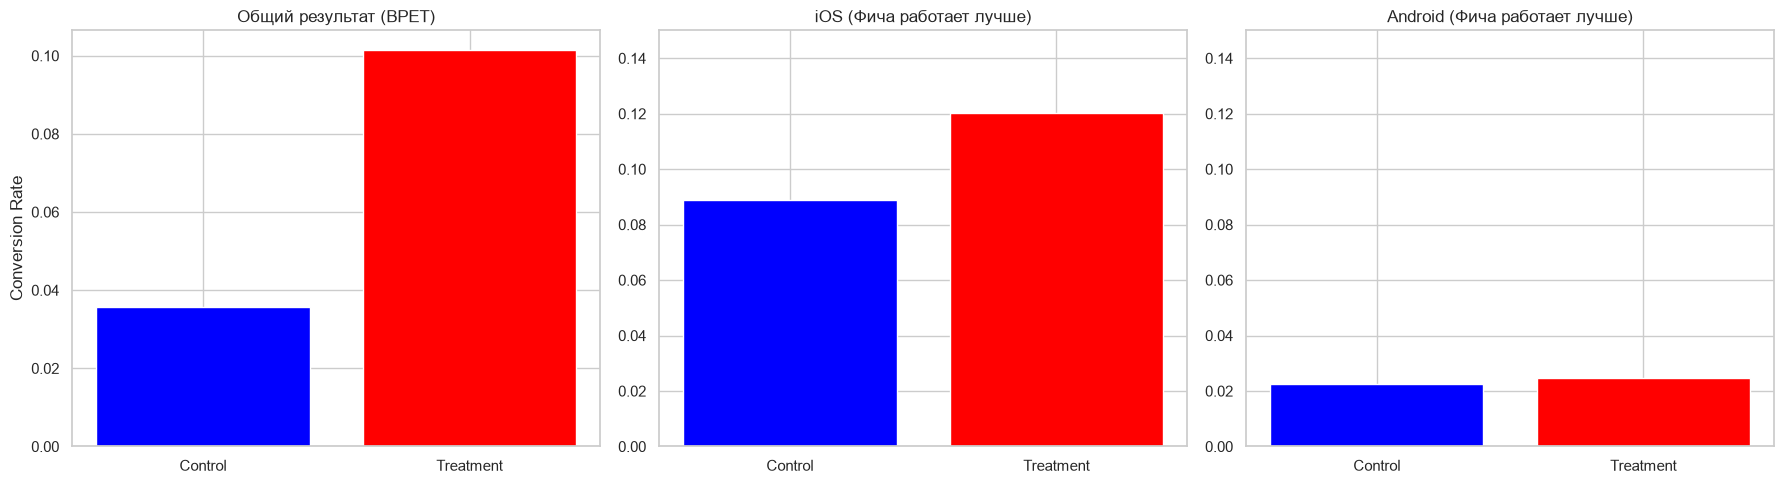

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Общий график (врет)
axes[0].bar(["Control", "Treatment"], [cr_control, cr_treatment], color=["blue", "red"])
axes[0].set_title("Общий результат (ВРЕТ)")
axes[0].set_ylabel("Conversion Rate")

# iOS
axes[1].bar(["Control", "Treatment"], [ios_cr_c, ios_cr_t], color=["blue", "red"])
axes[1].set_title("iOS (Фича работает лучше)")
axes[1].set_ylim(0, 0.15)

# Android
axes[2].bar(["Control", "Treatment"], [android_cr_c, android_cr_t], color=["blue", "red"])
axes[2].set_title("Android (Фича работает лучше)")
axes[2].set_ylim(0, 0.15)

plt.tight_layout()
plt.show()

In [13]:
print("Распределение платформ в Control:")
print(control["device"].value_counts(normalize=True).map("{:.1%}".format))

print("\nРаспределение платформ в Treatment:")
print(treatment["device"].value_counts(normalize=True).map("{:.1%}".format))

Распределение платформ в Control:
device
Android    80.0%
iOS        20.0%
Name: proportion, dtype: str

Распределение платформ в Treatment:
device
iOS        80.4%
Android    19.6%
Name: proportion, dtype: str


Если смотреть на тест в целом, Treatment проигрывает Control (например, 5% против 8%). Кажется, что фича плохая.

Но если разбить данные по платформам, мы видим, что на iOS Treatment лучше на 2 п.п., и на Android Treatment лучше на 2 п.п.

Причина: дисбаланс выборки. В группу Treatment случайно попало 80% пользователей iOS (где конверсия изначально высокая), а в Control — только 20%. Из-за этого средняя конверсия Treatment «просела», потому что там больше Android-пользователей.

Вывод: Фича работает, тест изначально был спроектирован с ошибкой (не учли стратификацию по платформам). Рекомендация: перезапустить тест с правильной рандомизацией (стратификация по device) или проанализировать результаты с поправкой на сегменты (например, через регрессию).